In [137]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs


# read the hdf5 file output_pv_div_latlon.nc
with h5py.File('output_pv_div_latlon.nc', 'r') as f:
    press = f['Pressure'][:]
    pv=f['PV'][5, :, :, :]
    lats = f['Latitude'][:]
    lons = f['Longitude'][:]

print(pv.shape)

(44, 294, 5293)


In [138]:
ipr= np.argmin(np.abs(press-1e5))
print(press[ipr]*1e-5)


# calculate reletive vorticity
omege_jupiter=1.758e-4
f=2*omege_jupiter*np.sin(np.radians(lats))

rv=pv[ipr,:,:]-f[:, np.newaxis]

print(rv.shape)


0.9639953906250001
(294, 5293)


posx and posy should be finite values
posx and posy should be finite values


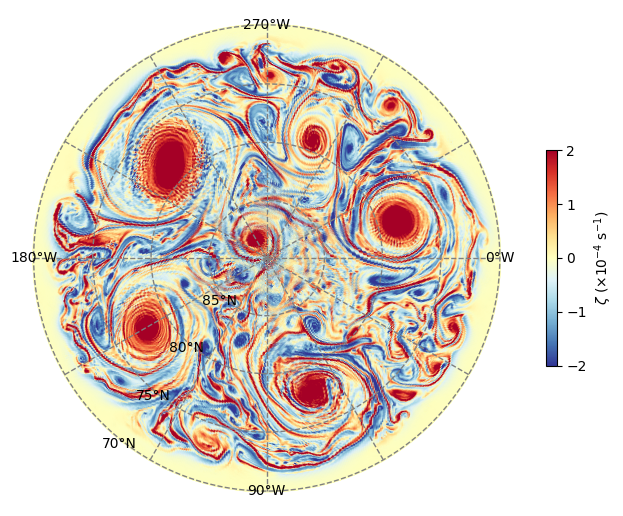

In [139]:
fig=plt.figure(figsize=(8, 8), dpi=100)
ax = plt.axes(projection=ccrs.NorthPolarStereo(central_longitude=-90))

ax.set_extent([-180, 180, 70, 90], ccrs.PlateCarree())
# plot data using a logarithmic color scale
# cn=ax.contourf(lon, lat, data,cmap='inferno', transform=ccrs.PlateCarree(), norm=LogNorm(vmin=0.01, vmax=0.6))

lons, lats = np.meshgrid(lons, lats)

ax.set_xlim(-2.4e6, 2.4e6)
ax.set_ylim(-2.4e6, 2.4e6)
# cn=ax.contourf(lons, lats, rv, cmap='RdYlBu_r', transform=ccrs.PlateCarree(), levels=np.linspace(-0.0002, 0.0002, 100), extend='both')
cn=ax.scatter(lons, lats, c=rv*10000, cmap='RdYlBu_r', transform=ccrs.PlateCarree(), vmin=-2, vmax=2, s=5, edgecolor='none')
clb=plt.colorbar(cn, ax=ax, shrink=0.35, aspect=20, orientation='vertical', label=r'$\zeta$ ($\times$10$^{-4}$ s$^{-1}$)')

# cax = fig.add_axes([0.8, 0.03, 0.1, 0.45])
# for spine in cax.spines.values():
#     spine.set_visible(False)
# cax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
# cax.set_facecolor('none')
# clb=plt.colorbar(cn, ax=cax, shrink=0.5, aspect=20, orientation='vertical', label=r'$\zeta$ ($\times$10$^{-4}$ s$^{-1}$)')


ax.set_aspect("equal")

for spine in ax.spines.values():
    spine.set_visible(False)

for lon in range(0, -359, -30):
    if lon % 90 == 0:

        ha="center"
        # if lon == 0 :
        #     ha="right"
        # if lon == -180 :
        #     ha="left"

        ax.text( lon, 70, f"{abs(lon)}°W",  color="k", transform=ccrs.PlateCarree(), rotation=0, ha=ha, va='center', zorder=5)


    ax.plot([lon]*100, np.linspace(70,90, 100), linestyle='--', color='gray', alpha=1, lw=1, transform=ccrs.Geodetic(), zorder=3)

for lat in range(70, 91, 5):
    ax.text(-90-35, lat+0.5, f"{abs(lat)}°N", alpha=1, color="k", transform=ccrs.PlateCarree(),ha='right', va='center',zorder=5)
    ax.plot( np.linspace(-180,180, 600),[lat]*600, linestyle='--', color='gray', alpha=1, lw=1, transform=ccrs.Geodetic(), zorder=3)

    # ax.text(-0.08, 1.02, f'{chr(i+97)}', transform=ax.transAxes, fontsize=18, fontweight='bold', va='top', ha='left')

# plt.title('JIRAM Data from PJ46 (North Pole)')
plt.show()